# Pelatihan model Fase 4 (arsitektur multi-head)

Notebook ini melatih ulang Fase 4 sel demi sel dengan fungsi yang sama persis seperti
`python -m src.phases.phase4_model` (semua dipanggil dari `src/phases/phase4_model.py`, tidak ada
logika yang ditulis ulang di sini). Bedanya hanya visibilitas: tiap tahap punya tabel dan grafik
sendiri, bukan sekadar baris log.

**Kenapa perlu dijalankan.** Katalog tumbuh dari 4.461 menjadi 39.652 baris tier `full` setelah
`detail.csv` diintegrasikan, sedangkan artefak di `Model/artifacts/` masih hasil pelatihan
2026-08-30 atas 4.460 dokumen dan 24 genre. Dashboard (AI Studio, Methodology) baru memakai data
terbaru setelah sel penyimpanan di Bagian 7 dijalankan.

## Perkiraan waktu

Perkiraan dihitung dari run 2026-08-30 (3.568 dokumen pengembangan) dikali sekitar 9, karena data
pengembangan sekarang 31.728 dokumen. Faktor itu cocok dengan satu-satunya angka yang sudah terukur
pada katalog baru: logreg butuh sekitar 8 menit, dulu 54 detik.

| Tahap | Run 2026-08-30 | Perkiraan sekarang | Catatan |
|---|---|---|---|
| Muat data + TF-IDF/SVD | | 1-3 menit | Spark membaca Parquet, lalu fit sklearn |
| Head A: logreg | 54 dtk | ~8 menit (terukur) | 3 kandidat x 3 fold + fit akhir |
| Head A: svm | 28 dtk | ~4 menit | LinearSVC dengan kalibrasi sigmoid |
| Head A: hybrid (TF-IDF + BGE) | 8 menit | 1-1,5 jam | encoding BGE di CPU, sekali untuk seluruh korpus lalu diambil dari memo |
| Head A: bilstm | 36 menit | ~5 jam | jaringan rekuren dilatih dari nol; skornya terendah di run lama |
| Head B, C, D | < 1 menit | beberapa menit | cosine similarity, KMeans, HistGradientBoosting |

**Urutan yang disarankan.** Jalankan pass cepat di Bagian 3.1 (logreg + svm) dulu untuk memastikan
semuanya jalan di katalog baru. Untuk run produksi yang ditinggal, pakai terminal, bukan notebook:

```bash
docker compose exec -d -e PHASE4_MODELS=logreg,svm,hybrid pipeline python -m src.phases.phase4_model
```

`PHASE4_MODELS` melewati BiLSTM; kosongkan untuk melatih keempat arsitektur. Notebook ini berjalan
di container `notebook` (<http://localhost:8888>).

## 1. Muat data latih

`load_training_frame()` membaca `novels_clean` lewat Spark, menyaring `has_text_signal`
(`token_count >= 3`), dan hanya menarik kolom yang dipakai model. Session Spark dibuka dan ditutup
di dalam fungsi itu.

Ada 16 baris tier `listing`: novel yang halaman detailnya tidak pernah berhasil diambil. Bab,
rating, dan tahunnya kosong, dan karena `series_id`-nya sintetis negatif, setelah diurutkan
mereka selalu berada paling atas. Pratinjau di bawah mengambil contoh dari kedua tier supaya NaN
itu tidak terbaca sebagai data yang hilang. Head A tetap memakai baris ini (teks dan genrenya ada);
Head D tidak, karena hanya dilatih pada rating tepercaya.

In [1]:
from src.phases.phase4_model import load_training_frame

pdf, stopwords = load_training_frame()
print(f"{len(pdf):,} baris x {len(pdf.columns)} kolom")
print(f"Genre unik (primary_genre): {pdf['primary_genre'].nunique()}")
print(f"Rating tepercaya (is_rated_reliable): {pdf['is_rated_reliable'].sum():,} / {len(pdf):,}")
print(f"Per tier: {pdf['metadata_tier'].value_counts().to_dict()}")

preview_cols = ["metadata_tier", "title", "primary_genre", "chapter_count",
                "rating_score", "weighted_rating", "token_count"]
pdf.groupby("metadata_tier", group_keys=False).head(3)[preview_cols]

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/certs/truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/certs/truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/15 08:22:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


2026-10-15 08:22:28 | INFO     | src.common.spark_session | SparkSession aktif | app=phase4-model | master=spark://spark-master:7077 | versi=3.5.3


...

26/10/15 08:22:32 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


2026-10-15 08:22:36 | INFO     | src.common.spark_session | SparkSession 'phase4-model' ditutup.


2026-10-15 08:22:36 | INFO     | phase4.model           | Data training dimuat: 39,660 baris, 26 kolom


39,660 baris x 26 kolom
Genre unik (primary_genre): 35
Rating tepercaya (is_rated_reliable): 23,256 / 39,660
Per tier: {'full': 39644, 'listing': 16}


,metadata_tier,title,primary_genre,chapter_count,rating_score,weighted_rating,token_count
0,listing,Transmigrated into a Waste Who Married the Vil...,Fantasy,NaN,NaN,NaN,92
1,listing,The Unmanned Era,Action,NaN,NaN,NaN,51
2,listing,The Guide To Unrequited Love,Comedy,NaN,NaN,NaN,73
16,full,Coiling Dragon,Action,806.0,4.5,4.4956,177
17,full,Martial God Asura,Action,6573.0,3.3,3.3017,143
18,full,Against the Gods,Action,2200.0,3.9,3.8993,180


### Palet & gaya (sama seperti `eda_visualisasi.ipynb`)

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = CAT[0], CAT[1], CAT[2], CAT[3]
_SEQ_STEPS = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", _SEQ_STEPS)
INK_PRIMARY, INK_SECONDARY, INK_MUTED, GRID, BASELINE, SURFACE = (
    "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb",
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY, "text.color": INK_PRIMARY, "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK_PRIMARY, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})


def style_ax(ax):
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.grid(axis="y", alpha=0.6)
    ax.tick_params(length=0)
    return ax


print("Palet & gaya siap.")

Palet & gaya siap.


## 2. Representasi bersama: TF-IDF ke SVD

Satu ruang fitur dipakai bersama oleh Head A sampai D, dan dilatih sekali di sini. TF-IDF memakai
1-2 gram karena banyak tag berupa frasa ("time loop", "weak strong"). Hasilnya dipadatkan dengan
Truncated SVD (LSA) 200 dimensi, supaya cosine similarity lebih tahan sinonim dan murah dihitung
saat inferensi.

In [3]:
from src.phases.phase4_model import build_genre_frame, build_representation

# Teks dibangun ulang dari kolom mentah dengan sensor NovelUpdates dipulihkan ("mu*der" -> "murder"),
# lewat fungsi yang sama dengan jalur inferensi. Tabel ini dipakai keempat head.
frame = build_genre_frame(pdf, stopwords)
vectorizer, svd, tfidf, embeddings = build_representation(frame["corpus_clean"])
print(f"TF-IDF   : {tfidf.shape[0]:,} x {tfidf.shape[1]:,} (sparsity {100*tfidf.nnz/(tfidf.shape[0]*tfidf.shape[1]):.4f}%)")
print(f"SVD      : {svd.n_components} komponen, {svd.explained_variance_ratio_.sum()*100:.2f}% varians terjelaskan")
print(f"Embedding: {embeddings.shape}")

2026-10-15 08:22:53 | INFO     | phase4.model           | Matriks TF-IDF: 39,660 x 30,000 (sparsity 0.4263%)


2026-10-15 08:23:03 | INFO     | phase4.model           | SVD 200 komponen | variansi terjelaskan: 15.31%


TF-IDF   : 39,660 x 30,000 (sparsity 0.4263%)
SVD      : 200 komponen, 15.31% varians terjelaskan
Embedding: (39660, 200)


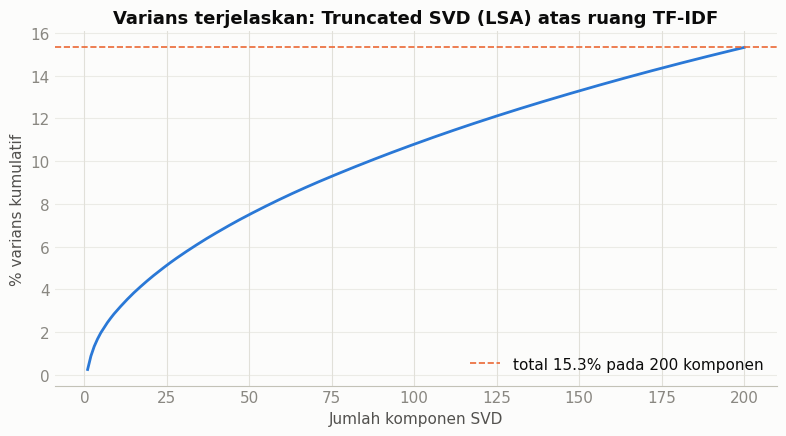

In [4]:
cum_var = np.cumsum(svd.explained_variance_ratio_) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(cum_var) + 1), cum_var, color=BLUE, linewidth=2)
ax.axhline(cum_var[-1], color=ORANGE, linestyle="--", linewidth=1.2,
           label=f"total {cum_var[-1]:.1f}% pada {len(cum_var)} komponen")
ax.set_xlabel("Jumlah komponen SVD")
ax.set_ylabel("% varians kumulatif")
ax.set_title("Varians terjelaskan: Truncated SVD (LSA) atas ruang TF-IDF")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()

## 3. Head A: genre tagger (klasifikasi multi-label)

Semua arsitektur dilatih dan diuji pada pembagian data yang sama (80/20 lewat `split_indices`,
`random_state` tetap), jadi perbandingannya adil. Ambang tiap genre disetel dari probabilitas
*out-of-fold* di set pengembangan. Arsitektur terbaik juga dipilih dari skor OOF itu, bukan dari
skor uji: set uji hanya dipakai untuk melaporkan angka akhir.

**Membandingkan dengan run lama.** Run 2026-08-30 mendapat F1 makro 0,536 (hybrid) pada 24 genre
dan 4.460 dokumen. Sekarang ada 35 genre dan sekitar 9 kali lebih banyak dokumen, jadi tugasnya
berbeda: angka baru yang lebih tinggi atau lebih rendah sama-sama bukan bukti model membaik atau
memburuk. Laporkan keduanya berdampingan di `Model/model_card.md`.

### 3.1 Pass cepat: logreg dan svm saja, tanpa BGE

In [5]:
from src.phases.phase4_model import train_genre_tagger

# Pass cepat: dua model linear saja. Jalankan sel ini untuk memastikan seluruh pipeline
# (fitur, ambang, evaluasi) beres sebelum pelatihan lengkap di 3.2.
genre_artifacts_quick, mlb_quick, metrics_a_quick = train_genre_tagger(pdf, names=["logreg", "svm"], frame=frame)
pd.DataFrame(metrics_a_quick["models"]).T[["f1_macro", "f1_micro", "precision_at_3", "threshold_mean"]]

2026-10-15 08:23:03 | INFO     | phase4.model           | Genre dipakai: 35 dari 35 (ambang >= 50 novel)


2026-10-15 08:23:03 | INFO     | phase4.model           | Pembagian data: pengembangan=31,728 (ambang via OOF 3-fold), uji=7,932


2026-10-15 08:23:03 | INFO     | model.embeddings       | Batas memo embedding dinaikkan ke 79320 entri.


2026-10-15 08:23:03 | INFO     | model.pipeline         |   [logreg] Logistic Regression — mencari konfigurasi terbaik ...


2026-10-15 08:24:25 | INFO     | model.pipeline         |       {'C': 0.5, 'class_weight': None} -> makro-F1 OOF 0.5958


...

2026-10-15 08:28:18 | INFO     | model.pipeline         |       {'C': 0.06, 'class_weight': None} -> makro-F1 OOF 0.6011


2026-10-15 08:28:18 | INFO     | model.pipeline         |   [svm] konfigurasi terpilih: {'C': 0.0354, 'class_weight': None}


2026-10-15 08:28:43 | INFO     | model.pipeline         |   [svm] UJI: F1 makro=0.6093 mikro=0.6718 P@3=0.8015 | ambang seragam 0,5: makro=0.5282


2026-10-15 08:28:43 | INFO     | model.pipeline         | Model terbaik menurut makro-F1 OOF: svm (OOF 0.6022, uji 0.6093)


,f1_macro,f1_micro,precision_at_3,threshold_mean
logreg,0.6027,0.667,0.7953,0.233
svm,0.6093,0.6718,0.8015,0.257


### 3.2 Pelatihan lengkap: model yang disajikan dashboard

Sel ini menghasilkan `genre_artifacts`, `mlb`, dan `metrics_a` untuk `DEFAULT_MODELS`: Logistic
Regression, Linear SVM, Random Forest, dan ensemble SVM + Random Forest (bobotnya dipilih dari
probabilitas OOF, tanpa pelatihan tambahan). Model neural riset (`hybrid`, `bilstm`) hanya dilatih
bila namanya ditambahkan ke `names`.

In [6]:
from src.phases.genre_models import DEFAULT_MODELS

genre_artifacts, mlb, metrics_a = train_genre_tagger(pdf, names=list(DEFAULT_MODELS), frame=frame)
pd.DataFrame(metrics_a["models"]).T[["f1_macro", "f1_macro_oof", "f1_micro", "precision_at_3", "threshold_mean"]]

2026-10-15 08:28:44 | INFO     | phase4.model           | Genre dipakai: 35 dari 35 (ambang >= 50 novel)


2026-10-15 08:28:44 | INFO     | phase4.model           | Pembagian data: pengembangan=31,728 (ambang via OOF 3-fold), uji=7,932


2026-10-15 08:28:44 | INFO     | model.pipeline         |   [logreg] Logistic Regression — mencari konfigurasi terbaik ...


2026-10-15 08:30:01 | INFO     | model.pipeline         |       {'C': 0.5, 'class_weight': None} -> makro-F1 OOF 0.5958


2026-10-15 08:31:15 | INFO     | model.pipeline         |       {'C': 0.25, 'class_weight': None} -> makro-F1 OOF 0.5970


...

2026-10-15 08:35:43 | INFO     | model.pipeline         |   [rf] konfigurasi terpilih: {'n_estimators': 60, 'max_leaf_nodes': 2000, 'k_features': 3000}


2026-10-15 08:36:14 | INFO     | model.pipeline         |   [rf] UJI: F1 makro=0.5522 mikro=0.6296 P@3=0.7410 | ambang seragam 0,5: makro=0.2629


2026-10-15 08:37:25 | INFO     | model.pipeline         |   [ensemble] bobot {'svm': 0.7, 'rf': 0.3} | OOF 0.6059 | UJI: F1 makro=0.6121 mikro=0.6738


2026-10-15 08:37:25 | INFO     | model.pipeline         | Model terbaik menurut makro-F1 OOF: ensemble (OOF 0.6059, uji 0.6121)


,f1_macro,f1_macro_oof,f1_micro,precision_at_3,threshold_mean
logreg,0.6027,0.597,0.667,0.7953,0.233
svm,0.6093,0.6022,0.6718,0.8015,0.257
rf,0.5522,0.5492,0.6296,0.741,0.221
ensemble,0.6121,0.6059,0.6738,0.8007,0.241


In [7]:
# Pakai hasil 3.2 bila sudah dijalankan; kalau belum, hasil pass cepat 3.1.
if "metrics_a" not in globals():
    genre_artifacts, mlb, metrics_a = genre_artifacts_quick, mlb_quick, metrics_a_quick
    print("Memakai hasil pass cepat 3.1:", ", ".join(metrics_a["models"]))
else:
    print("Memakai hasil pelatihan penuh 3.2:", ", ".join(metrics_a["models"]))
print("Arsitektur terpilih (F1 makro OOF tertinggi):", metrics_a["best_model"])

Memakai hasil pelatihan penuh 3.2: logreg, svm, rf, ensemble
Arsitektur terpilih (F1 makro OOF tertinggi): ensemble


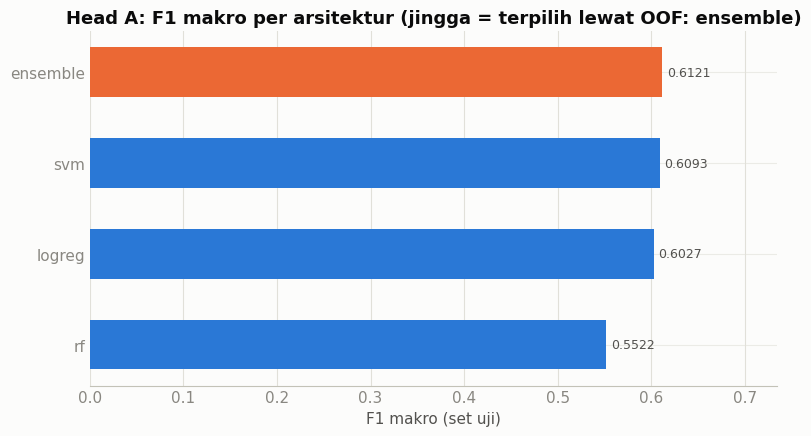

In [8]:
summary = pd.DataFrame(metrics_a["models"]).T[["f1_macro", "f1_micro", "precision_at_3"]].astype(float)
summary = summary.sort_values("f1_macro")
colors = [ORANGE if name == metrics_a["best_model"] else BLUE for name in summary.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(summary.index, summary["f1_macro"], color=colors, height=0.55)
for b, v in zip(bars, summary["f1_macro"]):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.4f}", va="center", fontsize=9,
            color=INK_SECONDARY)
ax.set_xlim(0, max(summary["f1_macro"]) * 1.2)
ax.set_title(f"Head A: F1 makro per arsitektur (jingga = terpilih lewat OOF: {metrics_a['best_model']})")
ax.set_xlabel("F1 makro (set uji)")
style_ax(ax)
plt.tight_layout()
plt.show()

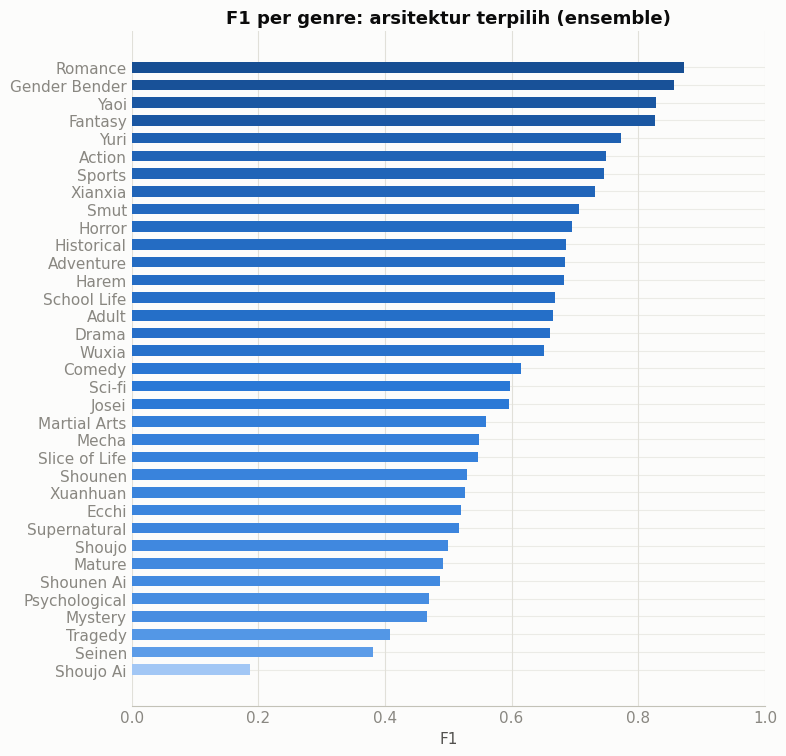

5 genre paling sulit: {'Shoujo Ai': 0.187, 'Seinen': 0.381, 'Tragedy': 0.408, 'Mystery': 0.466, 'Psychological': 0.469}
5 genre paling mudah: {'Yuri': 0.772, 'Fantasy': 0.827, 'Yaoi': 0.828, 'Gender Bender': 0.856, 'Romance': 0.873}


In [9]:
best_name = metrics_a["best_model"]
per_label = pd.Series(metrics_a["models"][best_name]["f1_per_label"]).sort_values()

fig, ax = plt.subplots(figsize=(8, max(5, 0.22 * len(per_label))))
norm = plt.Normalize(0, 1)
ax.barh(per_label.index, per_label.values, color=SEQ_BLUE(norm(per_label.values)), height=0.6)
ax.set_xlim(0, 1)
ax.set_title(f"F1 per genre: arsitektur terpilih ({best_name})")
ax.set_xlabel("F1")
style_ax(ax)
plt.tight_layout()
plt.show()
print("5 genre paling sulit:", per_label.head(5).round(3).to_dict())
print("5 genre paling mudah:", per_label.tail(5).round(3).to_dict())

## 4. Head B: recommender berbasis konten (evaluasi)

Dataset ini tidak punya `user_id` atau riwayat baca, jadi *collaborative filtering* tidak mungkin.
Rekomendasinya murni berbasis konten: cosine similarity pada embedding SVD. Karena tidak ada
ground-truth perilaku pembaca, kualitasnya diukur lewat proksi **genre overlap@k**: dari k tetangga
terdekat, berapa persen yang berbagi minimal satu genre dengan novel acuan.

In [10]:
from src.phases.phase4_model import evaluate_recommender

metrics_b = evaluate_recommender(embeddings, pdf, k=10)
print(f"Genre overlap@{metrics_b['k']} = {metrics_b['genre_overlap_at_k']:.4f} "
      f"(n sampel={metrics_b['n_sampled']:,})")

2026-10-15 08:37:26 | INFO     | phase4.model           | HEAD B | genre overlap@10 = 0.9490 (n sampel=500)


Genre overlap@10 = 0.9490 (n sampel=500)


## 5. Head C: clustering arketipe

k dipilih lewat silhouette score, dihitung pada subsampel 2.000 titik karena kompleksitasnya O(n²).

In [11]:
from src.phases.phase4_model import train_clustering

kmeans, metrics_c = train_clustering(embeddings, vectorizer, tfidf, pdf)
print(f"k terpilih = {metrics_c['best_k']} (silhouette {metrics_c['silhouette_by_k'][metrics_c['best_k']]:.4f})")

2026-10-15 08:37:28 | INFO     | phase4.model           |   k= 5 | silhouette=0.0261 | inertia=31681.8


2026-10-15 08:37:30 | INFO     | phase4.model           |   k= 6 | silhouette=0.0266 | inertia=31368.5


2026-10-15 08:37:33 | INFO     | phase4.model           |   k= 7 | silhouette=0.0285 | inertia=31113.2


2026-10-15 08:37:35 | INFO     | phase4.model           |   k= 8 | silhouette=0.0276 | inertia=30886.8


2026-10-15 08:37:37 | INFO     | phase4.model           |   k= 9 | silhouette=0.0274 | inertia=30687.8


...

2026-10-15 08:37:44 | INFO     | phase4.model           |   klaster 3 (n=4537): cultivation, martial, world, sect, immortal, master


2026-10-15 08:37:44 | INFO     | phase4.model           |   klaster 4 (n=5412): magic, world, fantasy, another world, another, fantasy world


2026-10-15 08:37:44 | INFO     | phase4.model           |   klaster 5 (n=8683): one, love, female, family, day, even


2026-10-15 08:37:44 | INFO     | phase4.model           |   klaster 6 (n=6994): love, love interests, interests, first, love first, characters


k terpilih = 7 (silhouette 0.0285)


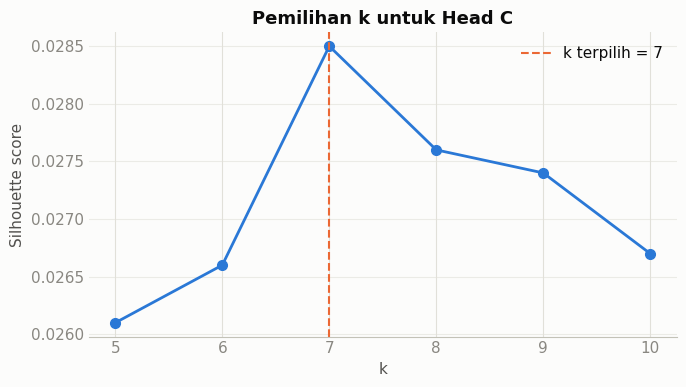

In [12]:
sil = pd.Series(metrics_c["silhouette_by_k"]).sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sil.index, sil.values, color=BLUE, marker="o", linewidth=2, markersize=7)
ax.axvline(metrics_c["best_k"], color=ORANGE, linestyle="--", linewidth=1.5,
           label=f"k terpilih = {metrics_c['best_k']}")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette score")
ax.set_title("Pemilihan k untuk Head C")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()

2026-10-15 08:37:45 | INFO     | matplotlib.category    | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-15 08:37:45 | INFO     | matplotlib.category    | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


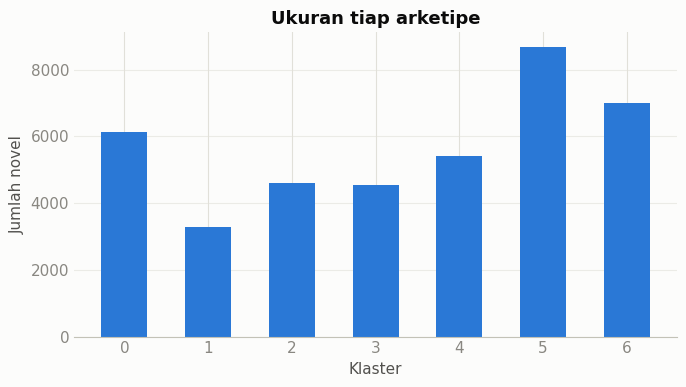

,size,avg_weighted_rating,avg_chapters,top_terms
cluster_id,,,,
0,6142,3.5927,192.0,"[day, modern day, modern, female, girl, male, ..."
1,3276,3.6000,149.4,"[european ambience, ambience, european, female..."
2,4616,3.6079,410.2,"[game, world, system, elements, game elements,..."
3,4537,3.5701,654.5,"[cultivation, martial, world, sect, immortal, ..."
4,5412,3.6141,301.5,"[magic, world, fantasy, another world, another..."
5,8683,3.5915,175.4,"[one, love, female, family, day, even, life, l..."
6,6994,3.8121,256.8,"[love, love interests, interests, first, love ..."


In [13]:
profiles = pd.DataFrame(metrics_c["profiles"]).set_index("cluster_id")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(profiles.index.astype(str), profiles["size"], color=BLUE, width=0.55)
ax.set_xlabel("Klaster")
ax.set_ylabel("Jumlah novel")
ax.set_title("Ukuran tiap arketipe")
style_ax(ax)
plt.tight_layout()
plt.show()

profiles[["size", "avg_weighted_rating", "avg_chapters", "top_terms"]]

## 6. Head D: estimator rating

Regresi `rating_score` dari konten ditambah fitur non-teks, dilatih hanya pada populasi rating
tepercaya (minimal 10 suara). `rating_votes` dan `reading_list_count` sengaja tidak dijadikan fitur:
keduanya bagian langsung dari rumus `weighted_rating`, jadi memakainya sama dengan membocorkan target.
Jumlah suara hanya dipakai sebagai bobot sampel saat latih.

Fiturnya embedding SVD, fitur numerik, skor ridge teks out-of-fold, dan tag multi-hot
(`Model/pipeline/rating.py`). Untuk angka evaluasi, TF-IDF dan SVD di-fit ulang tanpa baris uji,
jadi MAE di bawah benar-benar held-out; model akhir yang disimpan tetap memakai representasi
bersama dari Bagian 2.

In [14]:
from src.phases.phase4_model import train_rating_estimator

regressor, metrics_d, numeric_features = train_rating_estimator(embeddings, pdf, frame)
{k: v for k, v in metrics_d.items() if k != "hgb_params"}

2026-10-15 08:37:55 | INFO     | phase4.model           | Matriks TF-IDF: 35,008 x 30,000 (sparsity 0.4245%)


2026-10-15 08:38:04 | INFO     | phase4.model           | SVD 200 komponen | variansi terjelaskan: 15.28%


2026-10-15 08:39:17 | INFO     | phase4.model           | HEAD D | MAE=0.3250 (baseline 0.4151, +21.7%; konfigurasi lama 0.3395) | RMSE=0.4157 | R2=0.3544


{'trained': True,
 'n_train': 18604,
 'n_test': 4652,
 'mae': 0.325,
 'rmse': 0.4157,
 'r2': 0.3544,
 'baseline_mae': 0.4151,
 'baseline_rmse': 0.5174,
 'previous_config': {'mae': 0.3395,
  'rmse': 0.4307,
  'r2': 0.3071,
  'features': 'embedding SVD + numerik, tanpa bobot sampel'},
 'features': {'embedding_svd': 200,
  'numeric': 20,
  'ridge_text_score': 1,
  'tag_multi_hot': 678},
 'n_iter': 363,
 'sample_weight': 'log1p(rating_votes)',
 'evaluation_representation': 'TF-IDF + SVD di-fit tanpa baris uji',
 'target': 'rating_score (populasi >= 10 suara)',
 'improvement_over_baseline_pct': 21.71}

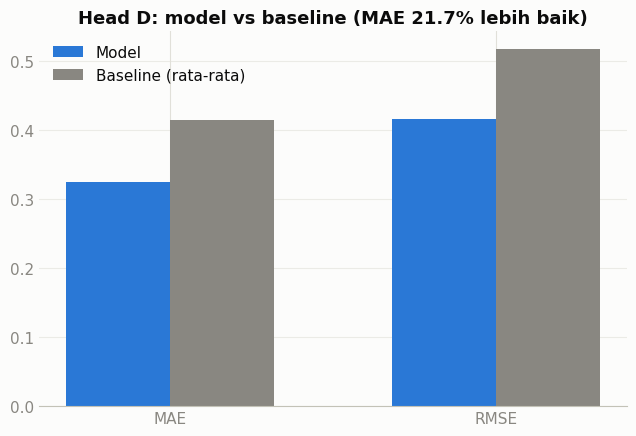

In [15]:
if metrics_d.get("trained"):
    labels_ = ["MAE", "RMSE"]
    model_vals = [metrics_d["mae"], metrics_d["rmse"]]
    base_vals = [metrics_d["baseline_mae"], metrics_d["baseline_rmse"]]
    x = np.arange(len(labels_))
    width = 0.32

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.bar(x - width / 2, model_vals, width, color=BLUE, label="Model")
    ax.bar(x + width / 2, base_vals, width, color=INK_MUTED, label="Baseline (rata-rata)")
    ax.set_xticks(x, labels_)
    ax.set_title(f"Head D: model vs baseline (MAE {metrics_d['improvement_over_baseline_pct']:.1f}% lebih baik)")
    ax.legend(frameon=False)
    style_ax(ax)
    plt.tight_layout()
    plt.show()
else:
    print("Head D dilewati:", metrics_d.get("reason"))

## 7. Simpan artefak dan unggah ke lake

Sel ini memanggil `persist_run()`, fungsi yang sama yang dipakai `phase4_model.run()`. Tidak ada
yang dilatih ulang: semua variabel diambil dari sel-sel di atas. Setiap berkas ditulis ke `*.tmp`
lalu diganti nama, dan `metrics.json` ditulis paling akhir. Dashboard memakai waktu ubah
`metrics.json` sebagai tanda bahwa satu set artefak sudah lengkap, jadi tidak pernah memuat
campuran versi lama dan baru.

`importlib.reload` dipakai supaya kernel yang sudah lama hidup memakai versi modul terbaru;
pada kernel baru baris itu tidak mengubah apa pun.

In [16]:
import importlib
from src.phases import phase4_model

phase4_model = importlib.reload(phase4_model)
metrics = phase4_model.persist_run(
    pdf, stopwords, vectorizer, svd, tfidf, embeddings,
    genre_artifacts, mlb, metrics_a, metrics_b, kmeans, metrics_c,
    regressor, metrics_d, numeric_features,
)
print(f"Artefak tersimpan di {phase4_model.ARTIFACT_DIR}: {metrics['n_documents']:,} dokumen, "
      f"{metrics['head_a_genre_tagger']['n_labels']} genre, model terpilih {metrics['head_a_genre_tagger']['best_model']}")
print("Salinan juga diunggah ke curated-data/models/.")

2026-10-15 08:40:42 | INFO     | phase4.model           | Katalog (39,660 baris) & embedding (39660, 200) tersimpan.


2026-10-15 08:40:42 | INFO     | phase4.model           | Artefak tersimpan: vectorizer.joblib (0.37 MB)


2026-10-15 08:40:44 | INFO     | phase4.model           | Artefak tersimpan: svd.joblib (44.10 MB)


2026-10-15 08:40:55 | INFO     | phase4.model           | Artefak tersimpan: genre_models.joblib (119.60 MB)


2026-10-15 08:40:55 | INFO     | phase4.model           | Artefak tersimpan: genre_binarizer.joblib (0.00 MB)


...

2026-10-15 08:40:59 | INFO     | src.common.storage     | Terunggah: metrics.json -> s3a://curated-data/models/metrics.json (0.02 MB)


2026-10-15 08:40:59 | INFO     | src.common.storage     | Terunggah: rating_regressor.joblib -> s3a://curated-data/models/rating_regressor.joblib (2.97 MB)


2026-10-15 08:41:00 | INFO     | src.common.storage     | Terunggah: svd.joblib -> s3a://curated-data/models/svd.joblib (44.10 MB)


2026-10-15 08:41:00 | INFO     | src.common.storage     | Terunggah: vectorizer.joblib -> s3a://curated-data/models/vectorizer.joblib (0.37 MB)


Artefak tersimpan di /opt/project/Model/artifacts: 39,660 dokumen, 35 genre, model terpilih ensemble
Salinan juga diunggah ke curated-data/models/.


## 8. Setelah artefak tersimpan

1. **Perbarui `Model/model_card.md`.** Tulis angka lama (F1 makro 0,536, 24 genre, 4.460 dokumen)
   berdampingan dengan angka baru, jangan ditimpa (lihat catatan di Bagian 3).
2. **Dashboard tidak perlu di-restart.** Begitu `metrics.json` berubah, AI Studio dan Methodology
   memuat artefak baru pada interaksi berikutnya.
3. **Versi sebelumnya tidak hilang sepenuhnya.** Artefak lokal tertimpa karena namanya sama, tetapi
   salinan lama tetap ada sebagai versi noncurrent di bucket `curated-data/models/` (versioning MinIO
   aktif, lihat audit tata kelola CMP-03).